# Homework 2: Multiple Linear Regression

**Research question:** How is salary associated with training hours, after
accounting for experience and education?

Use the revised salary extract described in `data/README.md` to extend
the analysis from Homework 1:

- Inspect types, duplicates, missing values, and variable ranges.
- Document the estimation samples and construct log salary.
- Explore relationships and investigate unusual observations.
- Add controls and compare coefficients and fit.
- Check the analysis and support your conclusions with numerical evidence.

**What to hand in:** this notebook with working code, saved outputs, and
completed **Answer 1–3** cells. Use your own explanations and refer to the
numbers your code produces. Add code cells where you need further checks.

First get the notebook running. Before changing the regression analysis,
record its initial results in Answer 2. Then review and repair the analysis,
complete all three answers, restart the kernel, run all cells, and save.
Read `README.md` for the deadline and submission instructions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

### Question 1 — Get the notebook running

Run the notebook and fix what prevents it from executing. Briefly report
the error, its cause, your repair, and how you verified the repair.

**Submit:** the corrected notebook and any changed project configuration
files, with a short explanation below.

### Answer 1

- Error and cause: the notebook had imported seaborn, but seaborn wasn't decleared in the pyproject.toml.
- Repair and verification: i added  "seaborn>=0.13.2", to the toml, saved, ran uv lock and uv sync to add the package, restarted the kernel and ran all.

## 1. Inspect the data and prepare the sample

Each row is a synthetic worker. `salary_k_eur` measures salary in thousands
of euros, `training_hours` measures hours, and experience and education are
measured in years. The other columns are not predictors in this analysis.

The file has no worker ID. Preserve its original DataFrame row labels so
that you can trace a record through the tables and plots. A row label
identifies a record within this file, not a person outside it.

In [2]:
workers = pd.read_csv("data/career_outcomes.csv")
workers.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   experience_years  212 non-null    float64
 1   education_years   223 non-null    float64
 2   training_hours    240 non-null    float64
 3   sector            240 non-null    str    
 4   remote            240 non-null    int64  
 5   ai_tool_use       240 non-null    float64
 6   salary_k_eur      240 non-null    float64
 7   promoted          240 non-null    int64  
dtypes: float64(5), int64(2), str(1)
memory usage: 15.1 KB


In [3]:
print("Rows:", len(workers))
print("Exact duplicate rows:", workers.duplicated().sum())
workers.isna().sum().rename("missing")

Rows: 240
Exact duplicate rows: 0


experience_years    28
education_years     17
training_hours       0
sector               0
remote               0
ai_tool_use          0
salary_k_eur         0
promoted             0
Name: missing, dtype: int64

In [4]:
required = ["salary_k_eur", "training_hours", "experience_years", "education_years"]
workers[required].describe().round(2)

,salary_k_eur,training_hours,experience_years,education_years
count,240.00,240.00,212.00,223.00
mean,75.68,39.68,5.92,15.55
std,15.68,16.09,3.34,1.73
min,36.20,0.00,1.20,12.00
25%,64.72,28.95,3.50,14.00
50%,74.45,39.30,5.10,16.00
75%,86.52,49.82,7.50,16.00
max,119.80,90.00,18.30,18.00


Inspect the counts and ranges before making exclusions. Missing values are
not zeros. Repeated values of a predictor do not make two workers duplicates.
A suspicious value needs investigation before it is corrected or deleted.

Count the available observations for each set of variables. Keep named
samples for observed salary and training, and for the full set of predictors.

In [5]:
pd.Series({
    "Salary and training observed": len(
        workers.dropna(subset=["salary_k_eur", "training_hours"])
    ),
    "Salary, training, and experience observed": len(
        workers.dropna(subset=["salary_k_eur", "training_hours", "experience_years"])
    ),
    "All model variables observed": len(workers.dropna(subset=required)),
}, name="available_rows")

Salary and training observed                 240
Salary, training, and experience observed    212
All model variables observed                 197
Name: available_rows, dtype: int64

In [6]:
salary_sample = workers.dropna(subset=["salary_k_eur", "training_hours"]).copy()
print("Excluded for missing salary or training:", len(workers) - len(salary_sample))

# Check observed values; missing predictor values remain missing.
assert not np.isinf(salary_sample[required]).any().any(), "Check infinite values."
assert salary_sample["salary_k_eur"].gt(0).all(), "Salary must be positive."
for column in required[1:]:
    assert salary_sample[column].dropna().ge(0).all(), "Check negative hours or years."
salary_sample["log_salary"] = np.log(salary_sample["salary_k_eur"])

complete_sample = salary_sample.dropna(subset=required).copy()
print("Rows with salary and training:", len(salary_sample))
print("Additional exclusions for missing predictors:", len(salary_sample) - len(complete_sample))
print("Rows with all model variables:", len(complete_sample))

Excluded for missing salary or training: 0
Rows with salary and training: 240
Additional exclusions for missing predictors: 43
Rows with all model variables: 197


## 2. Explore relationships before estimating

Follow up on the minimum salary from the summary table. Keep its original
row label, inspect its characteristics, and locate it in the scatterplot.
The scatterplot uses observed salary and training; the boxplot additionally
requires observed education.

In [7]:
lowest_salary_row = salary_sample["salary_k_eur"].idxmin()
salary_sample.loc[[lowest_salary_row], required + ["log_salary"]]

,salary_k_eur,training_hours,experience_years,education_years,log_salary
235,36.2,34.4,1.9,12.0,3.589059


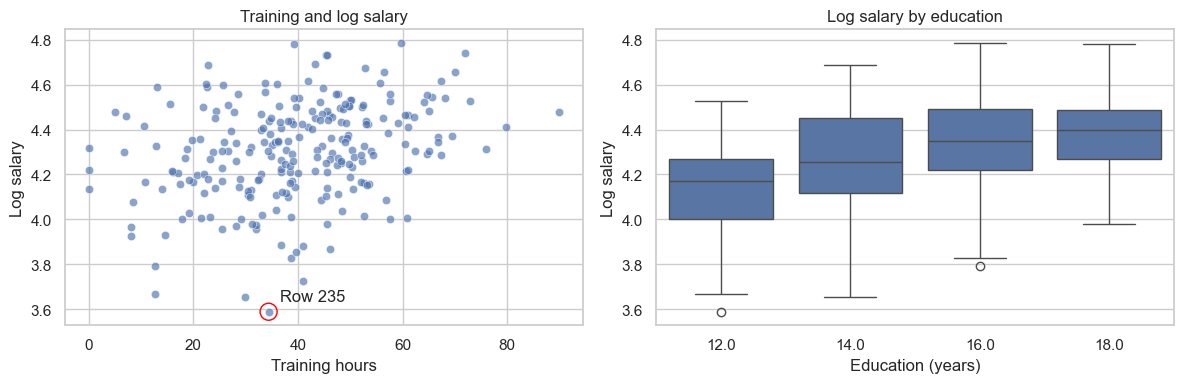

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=salary_sample, x="training_hours", y="log_salary",
                alpha=0.65, ax=axes[0])
# Use the original row label to locate the record inspected above.
point = salary_sample.loc[lowest_salary_row]
axes[0].scatter(point["training_hours"], point["log_salary"],
                facecolors="none", edgecolors="red", s=150)
axes[0].annotate(f"Row {lowest_salary_row}",
                 (point["training_hours"], point["log_salary"]),
                 xytext=(8, 8), textcoords="offset points")
sns.boxplot(data=salary_sample.dropna(subset=["education_years"]),
            x="education_years", y="log_salary", ax=axes[1])
axes[0].set(title="Training and log salary", xlabel="Training hours", ylabel="Log salary")
axes[1].set(title="Log salary by education", xlabel="Education (years)", ylabel="Log salary")
plt.tight_layout()
plt.show()

Retain unusual observations for the main analysis: this synthetic file gives
us no source evidence for a correction or an outlier-based exclusion.

## 3. Estimate and compare the specifications

Start with training hours, then add experience, then education. The sequence
asks how the training–salary association changes as these characteristics
are held constant. Experience and education enter numerically, with a constant
change in fitted log salary for each additional year.

All models include an intercept and use `cov_type="HC0"`. Question 3
links to the documentation for this option. Report the observation counts
alongside the coefficients and fit statistics.

**Before editing the regression analysis:** after resolving any execution
problems, copy the initial training coefficients and observation counts for
Models 1 and 3 into the first table in Answer 2. Keep that record when you
revise the code. Question 3 refers to your final reviewed analysis.

In [9]:
model_1 = smf.ols(
    "log_salary ~ training_hours", data=salary_sample, missing="drop"
).fit(cov_type="HC0")
model_2 = smf.ols(
    "log_salary ~ training_hours + experience_years",
    data=salary_sample, missing="drop"
).fit(cov_type="HC0")
model_3 = smf.ols(
    "log_salary ~ training_hours + experience_years + education_years",
    data=salary_sample, missing="drop"
).fit(cov_type="HC0")
assert model_3.nobs == len(complete_sample)

In [10]:
terms = ["training_hours", "experience_years", "education_years"]
regression_table = pd.DataFrame({
    "Training": model_1.params,
    "+ experience": model_2.params,
    "+ education": model_3.params,
}).reindex(terms)
regression_table.loc["R-squared"] = [model_1.rsquared, model_2.rsquared, model_3.rsquared]
regression_table.loc["Adjusted R-squared"] = [
    model_1.rsquared_adj, model_2.rsquared_adj, model_3.rsquared_adj,
]
regression_table.loc["Observations"] = [model_1.nobs, model_2.nobs, model_3.nobs]
regression_table.round(6).fillna("—")

,Training,+ experience,+ education
training_hours,0.004061,0.004646,0.004648
experience_years,—,0.032533,0.029515
education_years,—,—,0.034035
R-squared,0.092353,0.405965,0.470276
Adjusted R-squared,0.088539,0.400281,0.462042
Observations,240.0,212.0,197.000000


In [11]:
coefficient_change = model_3.params["training_hours"] - model_1.params["training_hours"]
print("Change in the training coefficient due to holding experience and education constant:")
print(f"{coefficient_change:+.6f} log-salary units per training hour")

Change in the training coefficient due to holding experience and education constant:
+0.000587 log-salary units per training hour


In [12]:
estimates = pd.DataFrame({"estimate": model_3.params, "robust_se": model_3.bse})
estimates.drop(index="Intercept").round(6)

,estimate,robust_se
training_hours,0.004648,0.000791
experience_years,0.029515,0.003094
education_years,0.034035,0.007023


### Question 2 — Check the coefficient-change claim

Before changing the regression analysis, record the initial training
coefficients and observation counts for Models 1 and 3 below.

Is the printed explanation of the coefficient change justified? Investigate
it, correct any misleading analysis, and show the numerical checks supporting
your conclusion. Add code cells if needed.

**Submit:** a table with the training coefficients and observation counts
for the fits you compare, plus a short explanation of what you changed and
what the comparison shows. Use at least six decimal places for coefficients.

In [13]:

# Estimated Model 1 using the same sample as Model 3
model_1_common = smf.ols(
    "log_salary ~ training_hours",
    data=complete_sample
).fit(cov_type="HC0")

# Compare the original and common-sample models
comparison = pd.DataFrame({
    "Training coefficient": [
        model_1.params["training_hours"],
        model_3.params["training_hours"],
        model_1_common.params["training_hours"],
        model_3.params["training_hours"]
    ],
    "Observations": [
        model_1.nobs,
        model_3.nobs,
        model_1_common.nobs,
        model_3.nobs
    ]
}, index=[
    "Original Model 1",
    "Original Model 3",
    "Model 1 (common sample)",
    "Model 3 (common sample)"
])

display(comparison.round(6))

print("Change due to sample restriction:",
      round(model_1_common.params["training_hours"]
            - model_1.params["training_hours"], 6))

print("Change due to adding controls:",
      round(model_3.params["training_hours"]
            - model_1_common.params["training_hours"], 6))


,Training coefficient,Observations
Original Model 1,0.004061,240.0
Original Model 3,0.004648,197.0
Model 1 (common sample),0.005732,197.0
Model 3 (common sample),0.004648,197.0


Change due to sample restriction: 0.001671
Change due to adding controls: -0.001084



### Answer 2

**Initial results — keep these after revising the code:**

| Original model | Training coefficient | Observations |
| --- | ---: | ---: |
| Model 1 | 0.004061 | 240 |
| Model 3 | 0.004648 | 197 |

**Checks and conclusion:**

To investigate whether the change in the training coefficient is caused by adding control variables, I estimated both models using the same complete-case sample of 197 observations.

| Model | Training coefficient | Observations |
| --- | ---: | ---: |
| Model 1 (common sample) | 0.005732 | 197 |
| Model 3 (common sample) | 0.004648 | 197 |

The original comparison shows an increase in the training coefficient from 0.004061 to 0.004648. However, the two original models use different samples.

After restricting Model 1 to the same 197 observations used by Model 3, its coefficient increases to 0.005732. When experience and education are added as controls, the coefficient decreases to 0.004648.

Therefore, the original comparison is misleading because it combines the effect of changing the sample with the effect of adding control variables. Using the same sample shows that adding experience and education reduces the training coefficient by 0.001084 log-salary units per training hour.


### Question 3 — Interpret the corrected result

Interpret the training coefficient in your final Model 3: give its value
and units, and state what is held constant.

For a brief documentation lookup, use the **Notes** in the
[statsmodels documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html)
to identify what `cov_type="HC0"` selects. One sentence is enough; no formula
or comparison of standard-error estimators is required.

**Submit:** a short coefficient interpretation and the one-sentence lookup answer.


### Answer 3

- Training coefficient interpretation: The training coefficient in Model 3 is 0.004648. This means that one additional hour of training is associated with approximately a 0.465% increase in salary, holding years of experience and education constant. This is an association and does not necessarily imply a causal effect.

- What `cov_type="HC0"` selects, according to the documentation:** HC0 selects heteroskedasticity-robust standard errors (White's heteroskedasticity-consistent covariance estimator), which account for possible non-constant variance of the regression errors.


## Submission checklist

- [ ] Answers 1–3 are complete, including the numerical checks for Question 2.
- [ ] I restarted the kernel, ran all cells without errors, and saved the outputs.
- [ ] I committed the notebook and any changed project configuration files,
  then pushed them to my own fork as described in `README.md`.